In [4]:
import anndata as ad
import re
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
from scipy import sparse
from scib_metrics.nearest_neighbors import pynndescent
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score


# st_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/cosmx_nsclc_Lung5-Rep1_adata_annotated_med_with_admix_probs.h5ad')
# sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/scRNA-seq/adata/GSE127465_tumor_integrated.h5ad')
# sc_data = ad.concat([ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_val_med_with_admix_probs.h5ad'),
#                     ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_train_med_with_admix_probs.h5ad')],
#                     join='outer')
sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_train_med_with_admix_probs.h5ad')

In [5]:
from tqdm.notebook import tqdm
tissue_key = 'harmony_spatial_tissue'
tissues = pd.Series(sc_data.obs[tissue_key].dropna().unique()).sort_values().to_list()
tissues

['Lung5_Rep1',
 'Lung5_Rep2',
 'Lung5_Rep3',
 'Lung6',
 'Lung9_Rep1',
 'Lung9_Rep2',
 'Lung12',
 'Lung13']

In [7]:
label_key = 'cell_type'
tissue_key = 'harmony_spatial_tissue'
target_removed_fractions = [0.01, 0.02, 0.05, 0.1]
leiden_resolution = 1.0
leiden_optimize_resolution = False
leiden_n_neighbors = 15
n_pcs = 50
library_size_target_sum = 1e4
n_jobs = 1
random_state = 0

import numpy as np
from scipy import sparse

def threshold_for_removed_fraction(probs, X, target_removed_frac: float):
    """
    Choose thr so that removing entries with probs >= thr removes ~target_removed_frac
    of TOTAL transcript counts (sum of counts), considering only X>0 entries.

    Returns
    -------
    thr : float
    achieved : float  (fraction of transcript counts removed using probs >= thr)
    """
    r = float(target_removed_frac)
    r = min(max(r, 0.0), 1.0)
    if r == 0.0:
        return np.inf, 0.0
    if r == 1.0:
        return -np.inf, 1.0

    # Pull (pvals, counts) only where X>0
    if sparse.issparse(X):
        Xcoo = X.tocoo()
        counts = Xcoo.data.astype(float)
        pvals = np.asarray(probs[Xcoo.row, Xcoo.col]).ravel().astype(float)
    else:
        X = np.asarray(X)
        probs = np.asarray(probs)
        nz = X > 0
        counts = X[nz].astype(float)
        pvals = probs[nz].astype(float)

    good = np.isfinite(pvals) & np.isfinite(counts) & (counts > 0)
    pvals = pvals[good]
    counts = counts[good]
    if counts.size == 0:
        raise ValueError("No expressed transcripts found (X>0).")

    total = float(counts.sum())
    target = r * total

    # Sort by probability descending, accumulate transcript counts
    order = np.argsort(pvals)[::-1]
    p_sorted = pvals[order]
    c_sorted = counts[order]
    cum = np.cumsum(c_sorted)

    idx = int(np.searchsorted(cum, target, side="left"))
    idx = min(idx, len(p_sorted) - 1)
    thr = float(p_sorted[idx])

    # Achieved fraction if you remove probs >= thr (important!)
    removed = float(c_sorted[p_sorted >= thr].sum())
    achieved = removed / total

    return thr, achieved

def _prepare_matrix_and_labels(X, labels, make_dense=False):
    labels = pd.Series(labels).astype('category')
    valid = ~labels.isna().to_numpy()
    X = X[valid]
    labels = labels[valid].cat.remove_unused_categories()
    if make_dense and sparse.issparse(X):
        X = X.toarray()
    return X, labels.to_numpy()


def _obsm_key_for_case(case_name):
    safe_case_name = re.sub(r'[^0-9A-Za-z_]+', '_', case_name).strip('_')
    return f'X_pca_metric_{safe_case_name}'


def _store_preprocessed_pcs(adata, obs_names, obsm_key, X_preprocessed):
    if obsm_key not in adata.obsm:
        adata.obsm[obsm_key] = np.full((adata.n_obs, n_pcs), np.nan, dtype=np.float32)
    row_idx = adata.obs_names.get_indexer(obs_names)
    if np.any(row_idx < 0):
        missing = obs_names[row_idx < 0].tolist()
        raise KeyError(f'Observations missing from result AnnData: {missing[:5]}')
    stored = adata.obsm[obsm_key]
    stored[row_idx, : X_preprocessed.shape[1]] = X_preprocessed.astype(np.float32, copy=False)
    adata.obsm[obsm_key] = stored


def preprocess_counts_for_metrics(X):
    adata = ad.AnnData(X=X.copy())
    sc.pp.normalize_total(adata, target_sum=library_size_target_sum)
    sc.pp.log1p(adata)
    n_comps = min(n_pcs, adata.n_obs - 1, adata.n_vars - 1)
    if n_comps < 1:
        raise ValueError('PCA metrics require at least two observations and two variables.')
    sc.pp.pca(adata, n_comps=n_comps, random_state=random_state)
    return adata.obsm['X_pca']


def _neighbors_for_scib_leiden_metrics(embedding):
    neighbors = pynndescent(
        embedding,
        n_neighbors=min(leiden_n_neighbors, embedding.shape[0]),
        random_state=random_state,
        n_jobs=n_jobs,
    )
    return neighbors


def cleaned_admixed_counts(adata, thresh):
    admixed = adata.X + adata.layers['admixed_counts']
    admix_probs = adata.layers['admix_probs']

    if sparse.issparse(admixed):
        cleaned = admixed.copy()
        row_idx, col_idx = cleaned.nonzero()
        probs_for_nonzero_counts = admix_probs[row_idx, col_idx]
        cleaned.data[np.asarray(probs_for_nonzero_counts).ravel() >= thresh] = 0
        cleaned.eliminate_zeros()
        return cleaned

    if sparse.issparse(admix_probs):
        admix_probs = admix_probs.toarray()

    return np.where(admix_probs >= thresh, 0, admixed)


def score_case(
    tissue,
    case_name,
    X,
    labels,
    result_adata,
    target_removed_fraction=np.nan,
    threshold=np.nan,
    achieved_removed_fraction=np.nan,
):
    valid_obs_names = pd.Index(labels.index)[~pd.Series(labels).isna().to_numpy()]
    X_raw, labels_prepared = _prepare_matrix_and_labels(X, labels)
    X_preprocessed = preprocess_counts_for_metrics(X_raw)
    obsm_key = _obsm_key_for_case(case_name)
    _store_preprocessed_pcs(result_adata, valid_obs_names, obsm_key, X_preprocessed)
    neighbors = _neighbors_for_scib_leiden_metrics(X_preprocessed)
    leiden_metrics = scib_metrics.nmi_ari_cluster_labels_leiden(
        neighbors,
        labels_prepared,
        optimize_resolution=leiden_optimize_resolution,
        resolution=leiden_resolution,
        n_jobs=n_jobs,
        seed=random_state,
    )
    return {
        'tissue': tissue,
        'case': case_name,
        'obsm_key': obsm_key,
        'target_removed_fraction': target_removed_fraction,
        'admix_prob_threshold': threshold,
        'achieved_removed_fraction': achieved_removed_fraction,
        'silhouette_score': silhouette_score(X_preprocessed, labels_prepared, metric='cosine'),
        'calinski_harabasz': calinski_harabasz_score(X_preprocessed, labels_prepared),
        'davies_bouldin': davies_bouldin_score(X_preprocessed, labels_prepared),
        'leiden_nmi_vs_cell_type': leiden_metrics['nmi'],
        'leiden_adjusted_rand_vs_cell_type': leiden_metrics['ari'],
    }


def score_tissue(tissue, adata, result_adata):
    admixed_counts = adata.X + adata.layers['admixed_counts']
    rows = [
        score_case(tissue, 'original_unadmixed', adata.X, adata.obs[label_key], result_adata),
        score_case(tissue, 'admixed', admixed_counts, adata.obs[label_key], result_adata),
    ]

    for target_removed_fraction in target_removed_fractions:
        thresh, achieved_removed_fraction = threshold_for_removed_fraction(
            adata.layers['admix_probs'],
            admixed_counts,
            target_removed_fraction,
        )
        rows.append(
            score_case(
                tissue,
                f'cleaned_admixed_removed_frac_{target_removed_fraction:g}',
                cleaned_admixed_counts(adata, thresh),
                adata.obs[label_key],
                result_adata,
                target_removed_fraction=target_removed_fraction,
                threshold=thresh,
                achieved_removed_fraction=achieved_removed_fraction,
            )
        )

    return rows


metrics_adata = sc_data
tissues = pd.Series(sc_data.obs[tissue_key].dropna().unique()).sort_values().to_list()
metric_rows = []
for tissue in tqdm(tissues[:2]):
    tissue_data = sc_data[sc_data.obs[tissue_key] == tissue].copy()
    metric_rows.extend(score_tissue(tissue, tissue_data, metrics_adata))

cell_type_separation = pd.DataFrame(metric_rows)
metrics_adata.uns['cell_type_separation_metrics'] = cell_type_separation

metrics_adata

  0%|          | 0/2 [00:00<?, ?it/s]

AnnData object with n_obs × n_vars = 318955 × 924
    obs: 'species', 'filename', 'sample', 'GSM_ID', 'cell_ID', 'Patient', 'Tissue', 'Barcoding emulsion', 'Library', 'Barcode', 'Total counts', 'Percent counts from mitochondrial genes', 'Most likely LM22 cell type', 'Major cell type', 'Minor subset', 'used_in_NSCLC_all_cells', 'x_NSCLC_all_cells', 'y_NSCLC_all_cells', 'used_in_NSCLC_and_blood_immune', 'x_NSCLC_and_blood_immune', 'y_NSCLC_and_blood_immune', 'used_in_NSCLC_immune', 'x_NSCLC_immune', 'y_NSCLC_immune', 'used_in_NSCLC_non_immune', 'x_NSCLC_non_immune', 'y_NSCLC_non_immune', 'used_in_blood', 'x_blood', 'y_blood', 'Barcode_Library', 'batch', 'cell_type', 'harmony_spatial_tissue', 'harmony_spatial_id', 'st_match_1_id', 'st_match_1_dist', 'st_match_1_x', 'st_match_1_y', 'st_match_2_id', 'st_match_2_dist', 'st_match_2_x', 'st_match_2_y', 'st_match_3_id', 'st_match_3_dist', 'st_match_3_x', 'st_match_3_y', 'sampled_st_id', 'sampled_st_x', 'sampled_st_y', 'selected_match_idx', 'spl

In [30]:
print(cell_type_separation.to_string())

        tissue                               case                                        obsm_key  target_removed_fraction  admix_prob_threshold  achieved_removed_fraction  silhouette_score  calinski_harabasz  davies_bouldin  leiden_nmi_vs_cell_type  leiden_adjusted_rand_vs_cell_type
0   Lung5_Rep1                 original_unadmixed                 X_pca_metric_original_unadmixed                      NaN                   NaN                        NaN          0.164894        2120.686307        2.963131                 0.701226                           0.549992
1   Lung5_Rep1                            admixed                            X_pca_metric_admixed                      NaN                   NaN                        NaN          0.151397        1970.407702        3.093658                 0.700398                           0.537130
2   Lung5_Rep1  cleaned_admixed_removed_frac_0.01  X_pca_metric_cleaned_admixed_removed_frac_0_01                     0.01              0.988719 

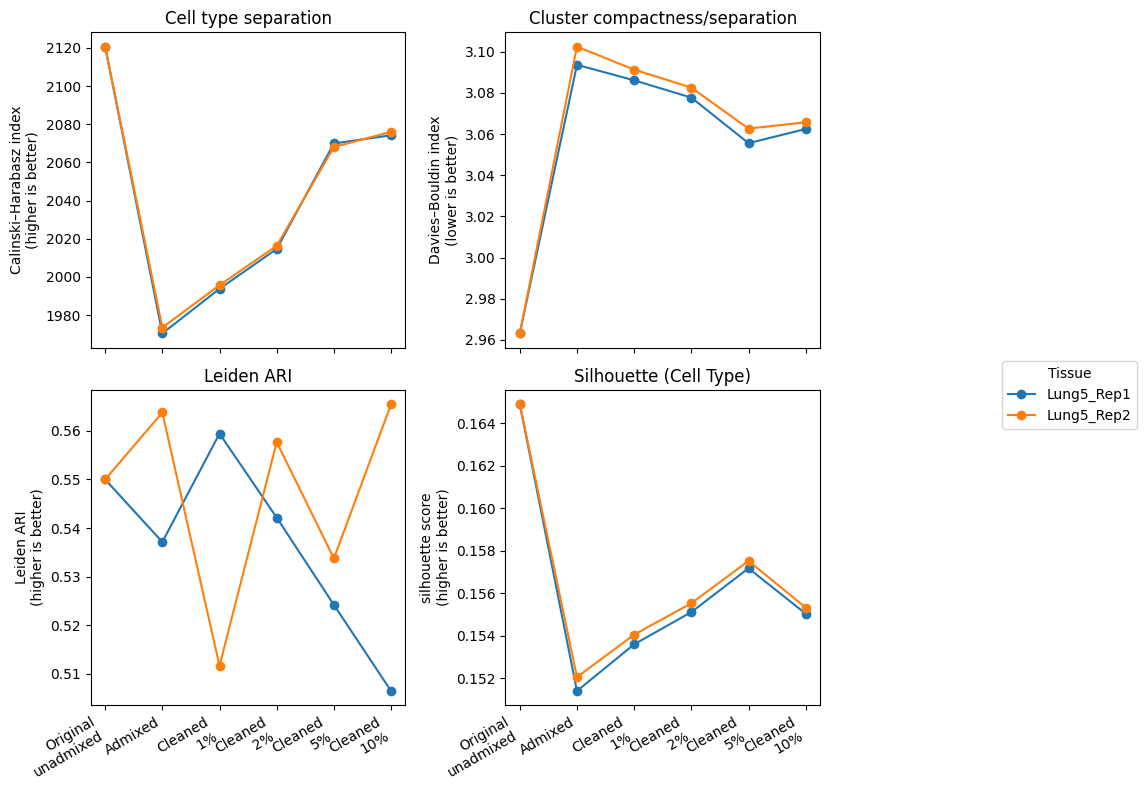

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# df = your dataframe

plot_df = cell_type_separation.copy()

# Define x-position/order manually
order = [
    "original_unadmixed",
    "admixed",
    "cleaned_admixed_removed_frac_0.01",
    "cleaned_admixed_removed_frac_0.02",
    "cleaned_admixed_removed_frac_0.05",
    "cleaned_admixed_removed_frac_0.1",
]

labels = [
    "Original\nunadmixed",
    "Admixed",
    "Cleaned\n1%",
    "Cleaned\n2%",
    "Cleaned\n5%",
    "Cleaned\n10%",
]

label_lookup = dict(zip(order, labels))
plot_df["setting"] = pd.Categorical(plot_df["case"], categories=order, ordered=True)
plot_df = plot_df.sort_values(["tissue", "setting"])
plot_df["x"] = plot_df["setting"].cat.codes

fig, axes_grid = plt.subplots(2, 2, figsize=(10, 8), sharex=True)
axes =  axes_grid.flat


def plot_metric(ax, metric, title, ylabel):
    for tissue, tissue_df in plot_df.groupby("tissue", sort=False):
        ax.plot(tissue_df["x"], tissue_df[metric], marker="o", label=tissue)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(np.arange(len(order)))
    ax.set_xticklabels([label_lookup[case] for case in order], rotation=30, ha="right")


# Calinski-Harabasz
plot_metric(
    axes[0],
    "calinski_harabasz",
    "Cell type separation",
    "Calinski–Harabasz index\n(higher is better)",
)

# Davies-Bouldin
plot_metric(
    axes[1],
    "davies_bouldin",
    "Cluster compactness/separation",
    "Davies–Bouldin index\n(lower is better)",
)

# Leiden ARI
plot_metric(
    axes[2],
    "leiden_adjusted_rand_vs_cell_type",
    "Leiden ARI",
    "Leiden ARI\n(higher is better)",
)

# Silhouette Score
plot_metric(
    axes[3],
    "silhouette_score",
    "Silhouette (Cell Type)",
    "silhouette score\n(higher is better)",
)

# for ax in axes:
#     ax.axvline(1, linestyle="--", linewidth=1, alpha=0.5)
#     ax.grid(True, axis="y", alpha=0.3)

handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="center left", bbox_to_anchor=(1.0, 0.5), title="Tissue")
plt.tight_layout(rect=[0, 0, 0.84, 1])
plt.show()

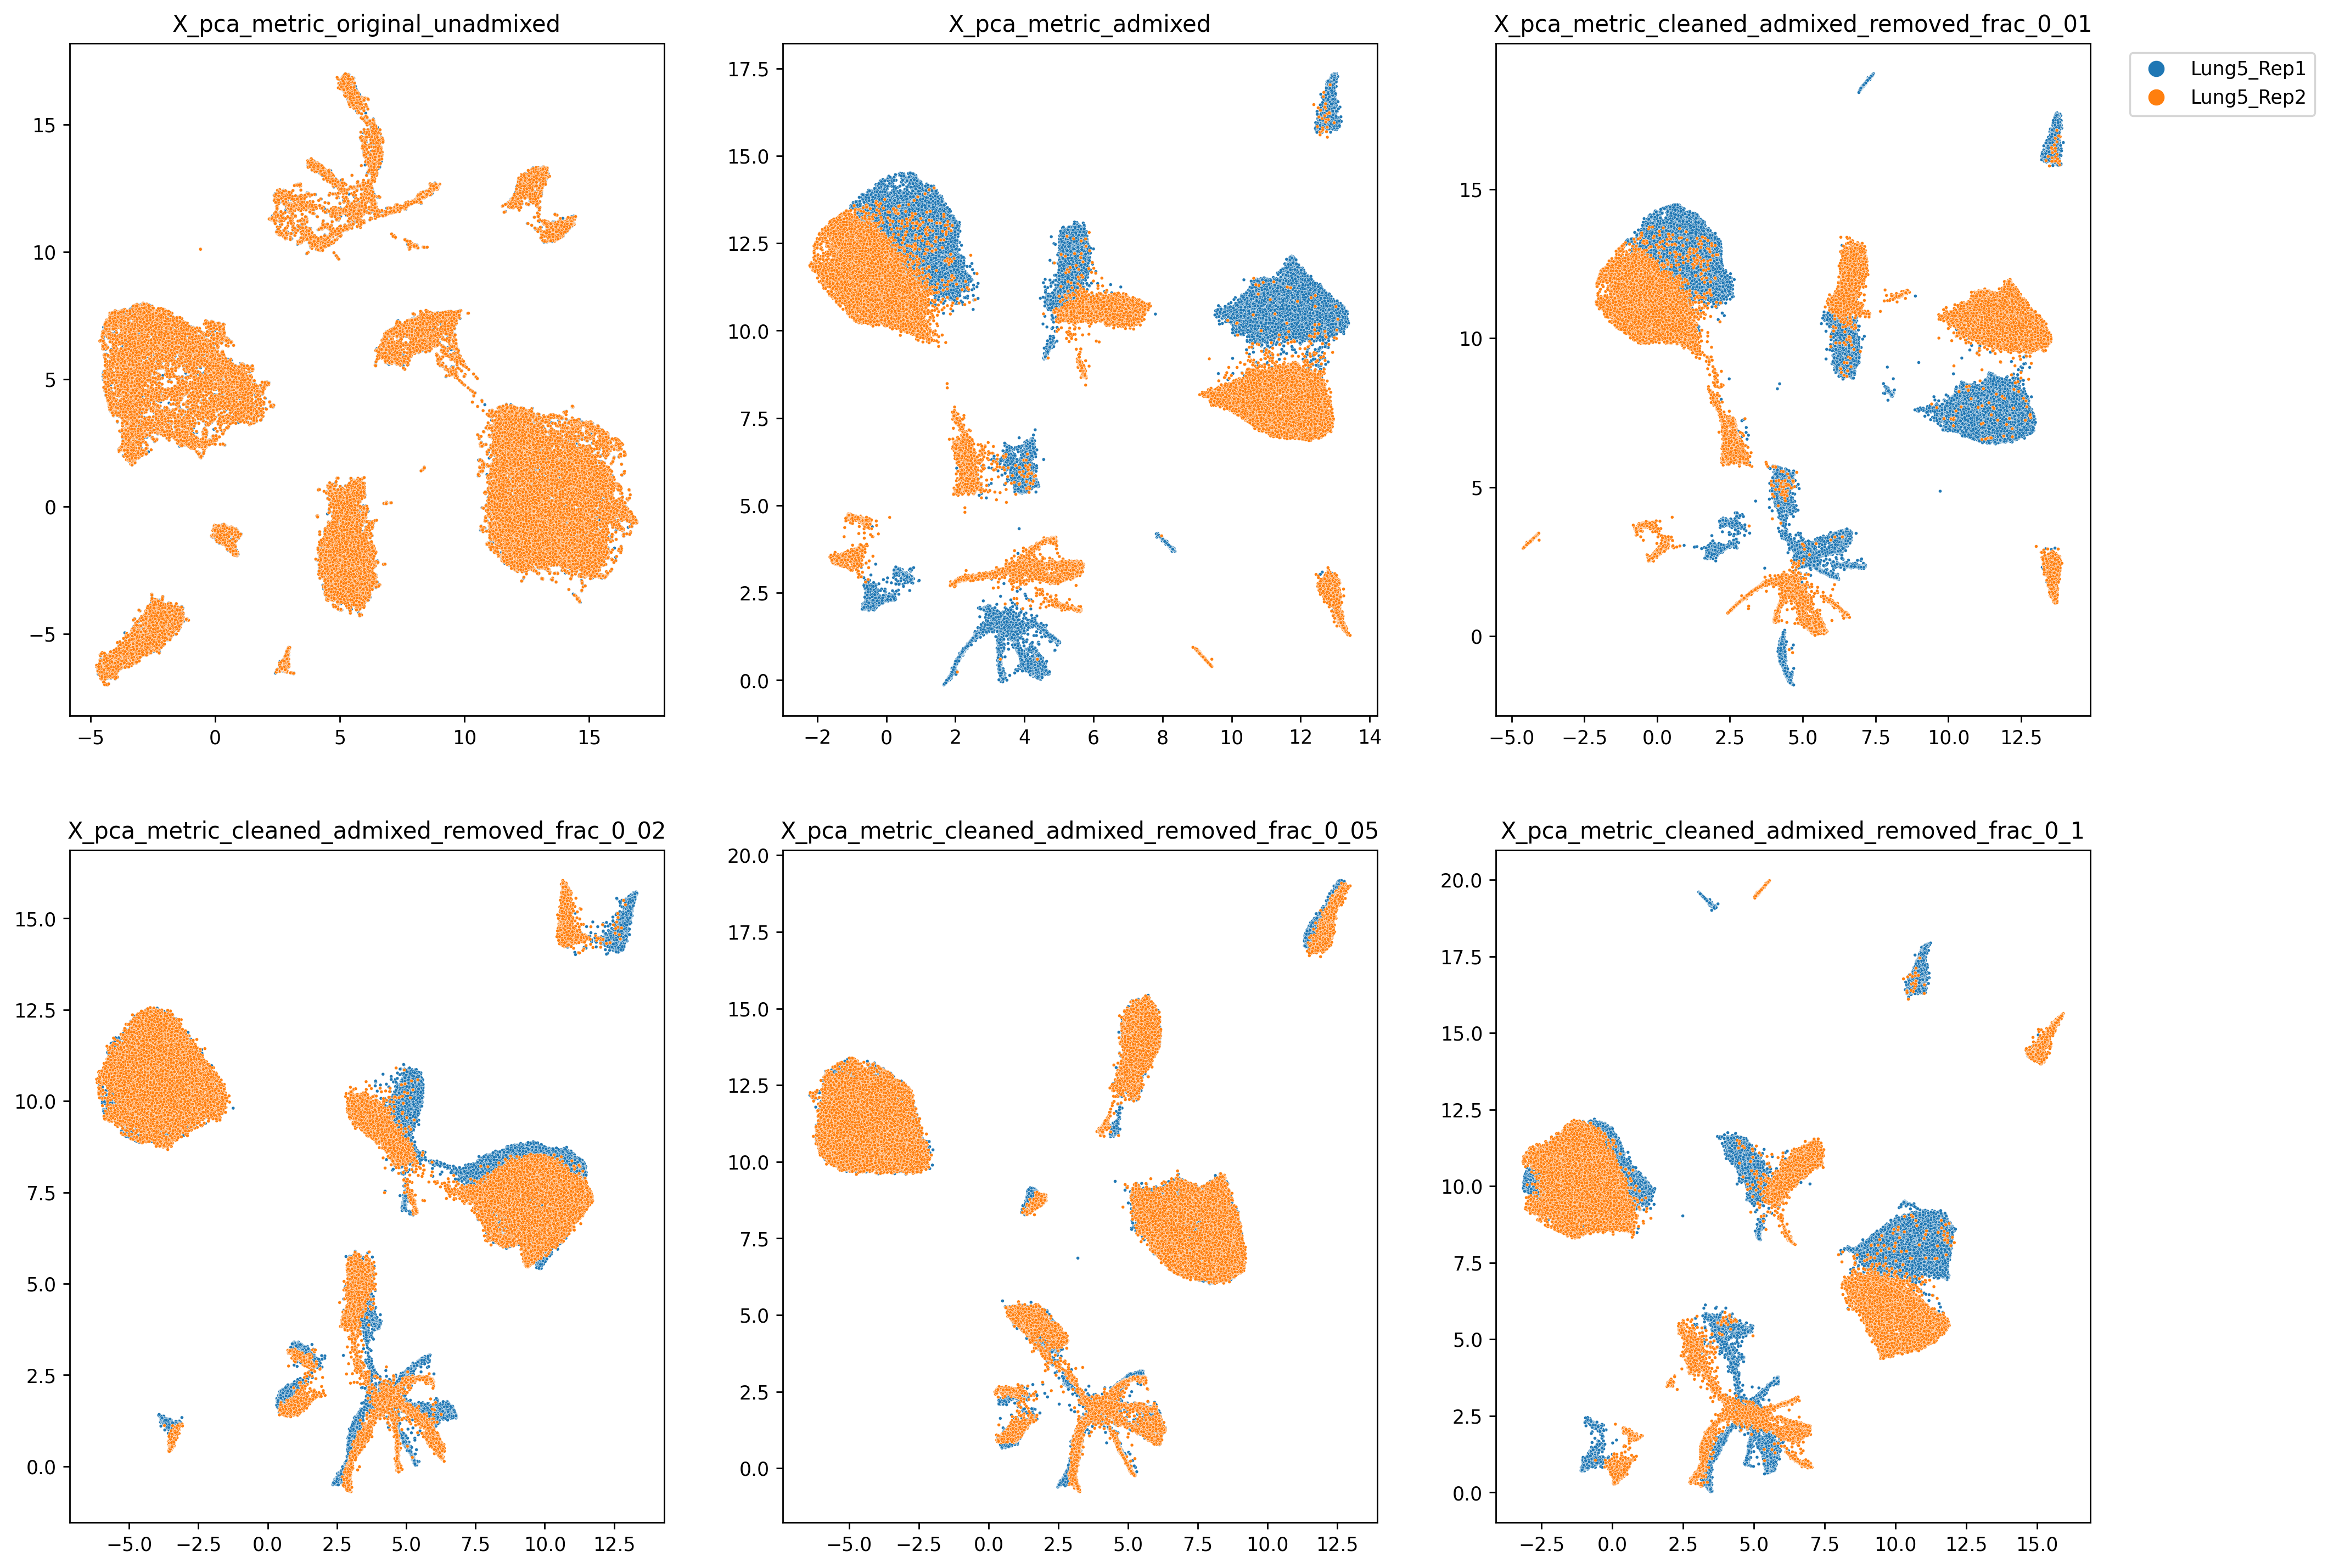

In [34]:
from umap import UMAP
import seaborn as sns
import matplotlib.pyplot as plt
settings = list(metrics_adata.obsm.keys())[1:]

fig,axes = plt.subplots(nrows=2,ncols=3,figsize=(19,14),dpi=250)
for i,setting in enumerate(settings):
    legend=False
    if i==2:
        legend=True
    set_adata = metrics_adata[np.sum(np.isnan(metrics_adata.obsm[setting]),axis=1)==0]
    coords = UMAP().fit_transform(set_adata.obsm[setting])
    ax = axes.flat[i]
    # sns.scatterplot(x=coords[:,0],y=coords[:,1],hue=set_adata.obs['cell_type'],s=3,ax=ax,legend=legend,style=set_adata.obs['harmony_spatial_tissue'])
    sns.scatterplot(x=coords[:,0],y=coords[:,1],hue=set_adata.obs['harmony_spatial_tissue'],s=3,ax=ax,legend=legend)
    ax.set_title(setting)
    if i==2:
        ax.legend(bbox_to_anchor=(1.05,1),markerscale=5)